In [53]:
import numpy as np
from matplotlib import colormaps
import matplotlib.pyplot as plt
from typing import Optional

from sklearn.neighbors import NearestNeighbors

In [38]:
def equicorr_mvn(
    n: int,
    d: int,
    rho: float,
    sigmas: Optional[np.ndarray] = None,
    mu: Optional[np.ndarray] = None,
    rng: Optional[np.random.Generator] = None
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """
    Generates n x d matrix X.
    X ~ N_d(mu, Sigma)
    Returns a tuple (X: (n, d), mu: (d,), Sigma: (d, d))

    mu = [0, ..., 0]^T if not specified
    mu shape is (d,)
    
    Sigma is an equicorrelation matrix.
    Sigma = D @ R @ D, where D are scales and R correlations.
    R shape is (d, d), it has unit variances and correlations equal rho.
    D = diag(sigmas),
    sigmas shape is (d,), sigmas represent marginal standard deviations.
    Sigma_{ii} = [DRD]_{ii} = sigmas^2_iR_{ii} = sigmas^2_i
    """
    if d < 1:
        raise ValueError(f"d = {d} must be greater or equal 1.")
    if n < 0:
        raise ValueError(f"n = {n} must be greater or equal 0.")
        
    # Positive definite condition for Sigma
    if d > 1 and not (-1/(d-1) < rho < 1):
        raise ValueError(f"rho = {rho} is not in the positive-definite range ({-1/(d-1)}, 1).")

    # mean of the multivariate normal distribution
    mu = np.zeros(d) if mu is None else np.asarray(mu)

    if mu.shape != (d,) or not np.all(np.isfinite(mu)):
        raise ValueError(f"mu must be a finite vector of shape ({d},).")

    sigmas = np.ones(d) if sigmas is None else np.asarray(sigmas)
    
    if sigmas.shape != (d,) or not np.all(np.isfinite(sigmas)):
        raise ValueError(f"sigmas must be a finite vector of shape ({d},).")

    if np.any(sigmas <= 0):
        raise ValueError("sigmas must contain strictly positive values.")
    
    rng = np.random.default_rng() if rng is None else rng

    # covariance matrix of the multivariate normal distribution
    I_d = np.eye(d)
    R = (1 - rho) * I_d + rho * np.ones((d, d))
    
    D = np.diag(sigmas)
    Sigma = D @ R @ D
    
    X = rng.multivariate_normal(mu, Sigma, n)

    return X, mu, Sigma

In [39]:
def nancov(X: np.ndarray):
    row_nan_mask = np.isnan(X).any(axis=1)
    return np.cov(X[~row_nan_mask], rowvar=False)

In [40]:
def coord_cond_distr(
    Y: np.ndarray,
    mus: np.ndarray,
    Sigma: np.ndarray
):
    """
    Calculates the conditional distribution
    of missing coordinated given the existing coordinate values
    
    Y: m x d matrix with missingness,
        observations are in rows,
        each row has to follow the same missingness pattern
    mus: (d, ) or (d, 1) vector of means
    Sigma: (d, d) covariance matrix
    """
    if Y.size == 0:
        raise ValueError("Empty input matrix Y provided.")

    # mask checking if Y is a vector
    is_vector = Y.ndim == 1 or (Y.ndim == 2 and 1 in Y.shape)
        
    # choose missing coordinate indices
    nan_mask = np.isnan(Y)
    
    # all observations must have a consistent missingness pattern
    # if more than one observation provided
    if (
        not is_vector
        # and Y has a consistent missingness pattern across rows
        # broadcast comparison of the first row against all rows
        and not np.all(nan_mask == nan_mask[0])
    ):
        raise ValueError("Inconsistent missingness pattern in the input matrix.")

    # the mask ultimately chooses a vector coordinates,
    # it is a per observation missing mask
    if not is_vector:
        nan_mask = nan_mask[0]

    # make mask's shape consistent (d,)
    nan_mask = nan_mask.ravel()

    if not nan_mask.any():
        raise ValueError("No missing values to estimate.")

    if nan_mask.all():
        raise ValueError("No observed values to condition on.")

    mus = mus.ravel()
    # recover dimension of a observation
    d = mus.size

    if d == 1:
        raise ValueError("Conditioning existing values looses meaning for d == 1.")

    I_d = np.eye(d)
    # existing values selector matrix
    A = I_d[~nan_mask]
    # missing values selector matrix
    B = I_d[nan_mask]

    mu_A = A @ mus
    mu_B = B @ mus

    Sigma_AA = A @ Sigma @ A.T
    Sigma_AB = A @ Sigma @ B.T
    Sigma_BA = Sigma_AB.T
    Sigma_BB = B @ Sigma @ B.T
    
    K = np.linalg.solve(Sigma_AA.T, Sigma_BA.T).T

    if is_vector:
        Y_obs = Y.ravel()[~nan_mask]
    else:
        Y_obs = Y[:, ~nan_mask]

    mu_cond = mu_B + (Y_obs - mu_A) @ K.T
    Sigma_cond = Sigma_BB - K@Sigma_AB

    return mu_cond, Sigma_cond

In [41]:
def pretty_2D_scatter(ax, x, y, alpha=0.5):
    ax.scatter(
        x, y,
        s=5,
        alpha=alpha
    )

    ax.spines[['top', 'right']].set_visible(False)

    '''
    grey = '0.7'
    # Axis lines
    for spine in ax.spines.values():
        spine.set_color(grey)

    # Tick marks and tick labels
    ax.tick_params(axis="both", colors=grey)
    '''
    return ax

In [42]:
def plot_vectors(ax, vectors, colors):
    if vectors.shape[1] > len(colors):
        raise ValueError("Not enough colors to draw vectors")

    for j in range(vectors.shape[1]):
        # ax.scatter(*eigvec_Sigma_X[:, j], c="orange")
        ax.quiver(
            *mu_X,
            *vectors[:, j],
            angles="xy",
            scale_units="xy",
            scale=1,
            color=colors[j],
            width=0.003,
            headlength=7,
            headwidth=5
        )
    return ax

## Generate data

In [43]:
seed = 42
rng = np.random.default_rng(seed)

n = 1000
d = 2

rho = 0.3
sigmas = [1, 1.095]

X, mu_X, Sigma_X = equicorr_mvn(n, d, rho, sigmas=sigmas, rng=rng)
# X, mu_X, Sigma_X = equicorr_mvn(n, d, rho, rng=rng)
print(Sigma_X)

eigval_Sigma_X, eigvec_Sigma_X = np.linalg.eigh(Sigma_X)

sample_Sigma_X = nancov(X)
eigval_sample_Sigma_X, eigvec_sample_Sigma_X = np.linalg.eigh(sample_Sigma_X)

[[1.       0.3285  ]
 [0.3285   1.199025]]


In [44]:
def apply_mcar(
    X: np.ndarray,
    cols: list[int], # or other iterable?
    p: float,
    rng: Optional[np.random.Generator] = None
):
    """
    Apply MCAR missingness with probability p
    on a block of columns with indexes cols.
    """
    if max(cols) >= X.shape[1]:
        raise ValueError(f"{max(cols)} column index out of bounds.")
    # cols = np.asarray(cols)

    X_mcar = X.copy()
    
    rng = np.random.default_rng() if rng is None else rng

    missing_rows = rng.binomial(1, p, X.shape[0]).astype(bool)
    missing_rows_idx = np.flatnonzero(missing_rows)
    
    X_mcar[np.ix_(missing_rows_idx, cols)] = np.nan

    return X_mcar, missing_rows_idx

## Apply missingness

In [45]:
p = 0.3
missing_cols_idx = np.array([1])
X_mcar, missing_rows_idx = apply_mcar(X, missing_cols_idx, p, rng)
sample_p = (np.isnan(X_mcar).sum(axis=0) / X.shape[0])[missing_cols_idx]
# check missingness
assert np.allclose(sample_p, p, atol=1e-1)

## Impute

### Unconditional mean

In [46]:
X_imp_umean = X_mcar.copy()
X_mcar_sample_mus = np.nanmean(X_mcar, axis=0)
missing_grid = np.ix_(missing_rows_idx, missing_cols_idx)
X_imp_umean[missing_grid] = X_mcar_sample_mus[missing_cols_idx]

### Conditional mean

In [47]:
X_mcar_sample_cov = nancov(X_mcar)
imp_cond_means, imp_cond_Sigma = coord_cond_distr(X_mcar[missing_rows_idx], X_mcar_sample_mus, X_mcar_sample_cov)
X_imp_cmean = X_mcar.copy()
X_imp_cmean[missing_grid] = imp_cond_means

### Stochastic imputation

In [48]:
res_mus = np.zeros(missing_cols_idx.size)
X_imp_stoch = X_mcar.copy()
X_imp_stoch[missing_grid] = imp_cond_means + rng.multivariate_normal(res_mus, imp_cond_Sigma, missing_rows_idx.size)

## Eigendecomposition analysis

In [49]:
imps = ["umean", "cmean", "stoch"]
datasets = [X_imp_umean, X_imp_cmean, X_imp_stoch]
datasets = dict(zip(imps, datasets))
sample_Sigma = {}
eigvals = {}
eigvecs = {}
for imp, ds in datasets.items():
    sample_Sigma[imp] = nancov(ds)
    eigvals[imp], eigvecs[imp] = np.linalg.eigh(sample_Sigma[imp])

A unit vectors dot product is:
$$
u^Tv = \cos(\angle(u,v))
$$
and
$$
u^Tv < 0 \Rightarrow \angle(u,v) > 90^\circ.
$$
Eigenvactors make an orthonormal basis. Flipping a sign of an eigenvector doesn't change that, the basis spans the same space and defines the same PCA axis.
$$(-u)^Tv = -u^Tv = 0$$
so the vectors stay perpendicular and are still of length 1.

Those properties are used to align eigenvectors so they point in similar direction along an axis.

In [50]:
def align_vector_directions(us, vs):
    """
    Aligns the direction of vs with us.
    It is assumed vectors are in columns
    """
    dot_prods = np.sum(us * vs, axis=0)
    signs = np.where(dot_prods > 0, 1, -1)

    return vs * signs

In [51]:
eigvec_sample_Sigma_X = align_vector_directions(eigvec_Sigma_X, eigvec_sample_Sigma_X)
for imp, _ in datasets.items():
    eigvecs[imp] = align_vector_directions(eigvec_Sigma_X, eigvecs[imp])

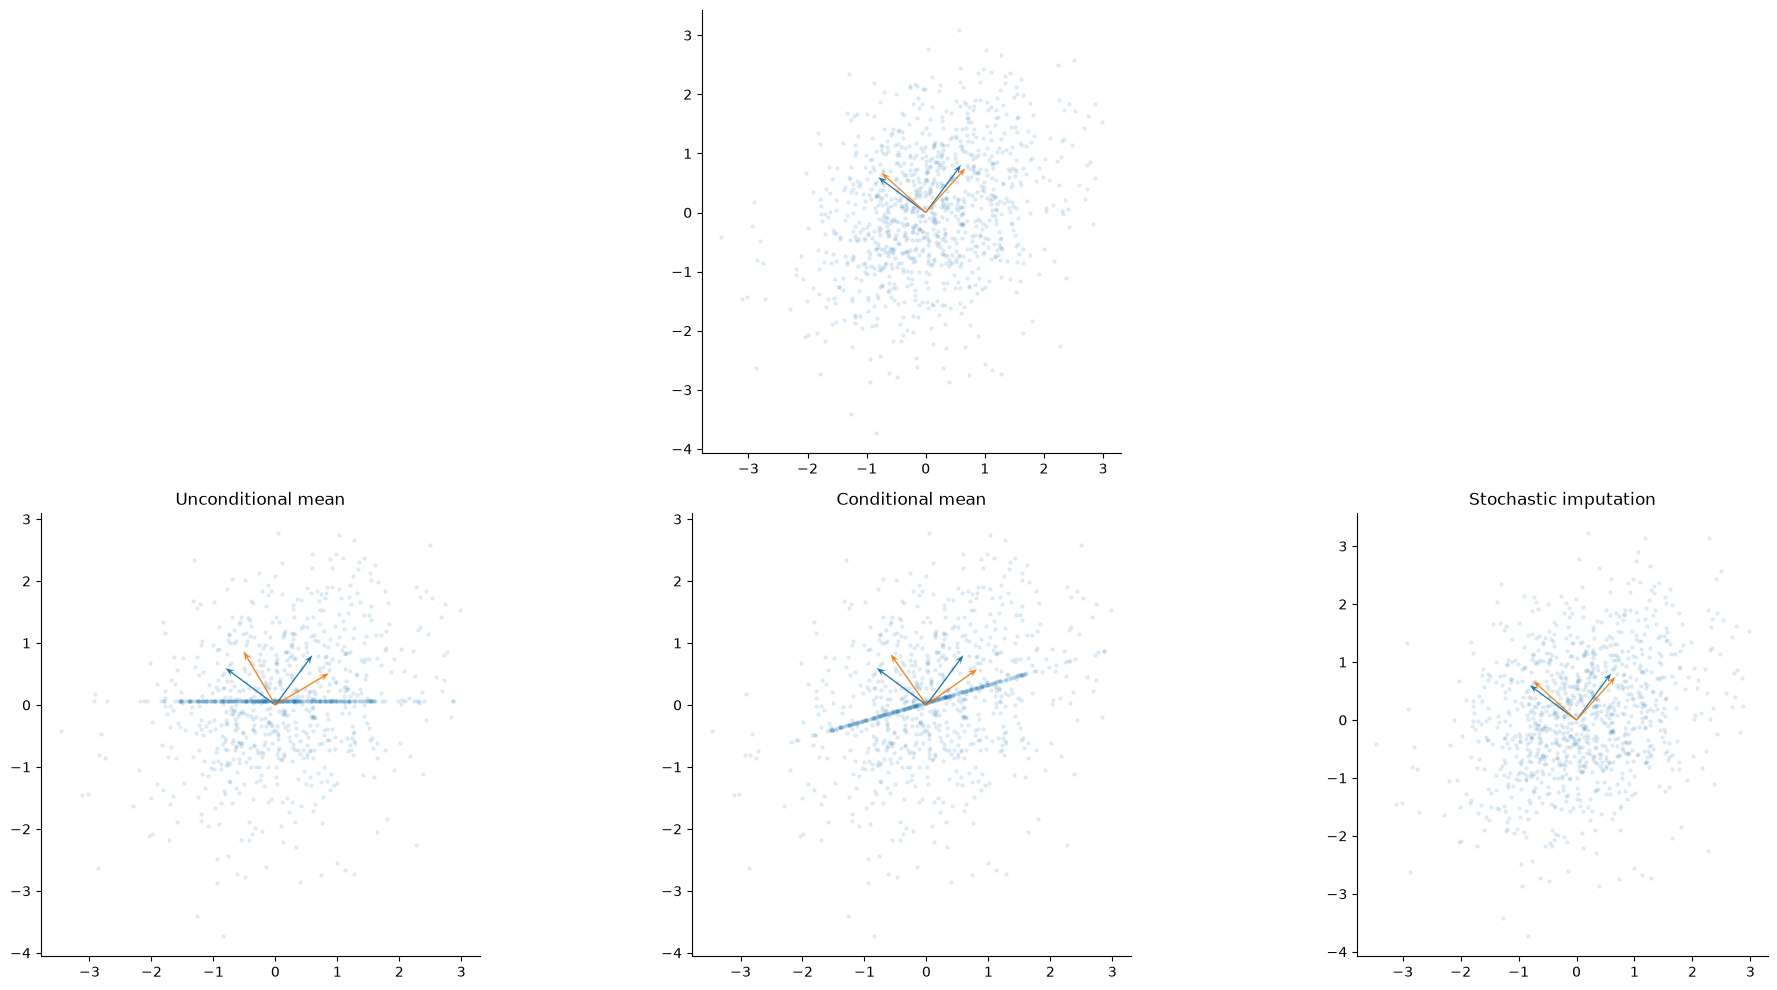

In [56]:
fig, axs = plt.subplots(2, 3, figsize=(20,10))
axs[0,0].set_visible(False)
axs[0,2].set_visible(False)

# TODO set limits so vectors are not cropped

### truth against sample eigenvectors ###
pretty_2D_scatter(axs[0,1], X[:,0], X[:,1], alpha=0.1)

vectors = np.hstack((eigvec_Sigma_X, eigvec_sample_Sigma_X))
colors = [colormaps["tab10"](c) for c in range(vectors.shape[1] // 2) for _ in range(2)]
plot_vectors(axs[0,1], vectors, colors)

### truth against eigenvectors from imputed ###
imp_names = [
    "Unconditional mean",
    "Conditional mean",
    "Stochastic imputation"
]
titles = dict(zip(imps, imp_names))
for i, (imp, ds) in enumerate(datasets.items()):
    pretty_2D_scatter(axs[1,i], ds[:,0], ds[:,1], alpha=0.1)

    vectors = np.hstack((eigvec_Sigma_X, eigvecs[imp]))
    plot_vectors(axs[1,i], vectors, colors)
    axs[1,i].set_title(titles[imp])

for ax in axs.flatten():
    ax.set_aspect("equal", adjustable="box")

fig.tight_layout()
plt.show()

## Neighbourhood analysis

In [59]:
X_NN = NearestNeighbors(n_neighbors=15 + 1).fit(X).kneighbors(X, return_distance=False)

In [62]:
k = 15
NN = {}
for imp, ds in datasets.items():
    NN[imp] = NearestNeighbors(n_neighbors=k + 1).fit(ds).kneighbors(ds, return_distance=False)